In [1]:
import firedrake
import numpy as np
import pickle as pkl
from numpy import pi as π
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
import firedrake
from firedrake import Constant, inner, sqrt, tr, grad, div, as_vector, exp,sym, as_vector, dx, ds, Mesh, Function, project, TransferManager
import meshpy, meshpy.geometry, meshpy.triangle
import irksome
from irksome import Dt
from scipy.signal import detrend
import copy
import matplotlib
import irksome
from irksome import Dt
import matplotlib.pyplot as plt
import pandas as pd
import scipy
import pickle as pkl
import tqdm
import emcee
import corner
import itertools
import xarray
import dtscalibration
import glob
from rasterio.plot import show
import matplotlib.colors as mcolors
import matplotlib.cm as cm
import os
import sys
from pyproj import Transformer
module_path = os.path.abspath(os.path.join('..'))
if module_path not in sys.path:
    sys.path.append(module_path)

from scripts.AH_temp_funcs import *
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from mpl_toolkits.basemap import Basemap
import shapefile as sf

import rasterio
from rasterio.enums import Resampling
from rasterio.mask import mask

from firedrake.checkpointing import DumbCheckpoint

from firedrake import *

### Import our homemade functions ###
import scripts.model_modules
from scripts.mesh_generating import *

import cartopy.crs as ccrs
from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar
import matplotlib.patheffects as pe
from matplotlib.patches import Rectangle
from matplotlib.collections import PatchCollection

%matplotlib widget

In [2]:
src_bed_coarse = rasterio.open("Meshes/ThreeD_meshing/bedmachine_ian_merged_bed_large_aoi_8m_aligned_fixed.tif")
bed_dem = src_bed_coarse.read()

src_surf_coarse = rasterio.open("Meshes/ThreeD_meshing/rema_large_aoi_align_fixed.tif")
surf_dem = src_surf_coarse.read()

src_imagery = rasterio.open('imagery/LIMA_virtual_Mosaic_15m.tif')
image_data = src_imagery.read()

ice_thickness = surf_dem - bed_dem
ice_thickness[ice_thickness < 10] = np.nan

In [7]:
upscale_factor_fine = 1/200
src_bed_fine_path = "Meshes/crop_aoi/main_boreholes_aoi/main_boreholes_aoi_fix_bed.tif"
src_surf_fine_path = "Meshes/crop_aoi/main_boreholes_aoi/main_boreholes_aoi_fix_surf.tif"
layer_num=5

In [6]:
mesh_fine = mesh_creator(src_bed_fine_path, src_surf_fine_path, resamp_factor=upscale_factor_fine, layers=layer_num)
x_src, y_src, z_src = SpatialCoordinate(mesh_fine)
mesh_fine.tolerance = 1e-10

pressure_space = firedrake.FunctionSpace(mesh_fine, "CG", 1)
velocity_space = firedrake.VectorFunctionSpace(mesh_fine, "CG", 3)
Y = velocity_space * pressure_space
flow = firedrake.Function(Y)

chk = DumbCheckpoint("Saved_Models/coarse_mesh_flow_final_model", mode=FILE_READ)
chk.load(flow, name="coarse_mesh_flow")

/opt/firedrake/firedrake/checkpointing.py:103: DeprecationWarning: DumbCheckpoint class will soon be deprecated; use CheckpointFile class instead.
  warnings.warn("DumbCheckpoint class will soon be deprecated; use CheckpointFile class instead.",


Error: error code 79
[0] VecLoad() at /opt/petsc/src/vec/vec/interface/vector.c:1170
[0] VecLoad_Default() at /opt/petsc/src/vec/vec/utils/vecio.c:219
[0] VecLoad_HDF5() at /opt/petsc/src/vec/vec/utils/vecio.c:137
[0] PetscViewerHDF5Load() at /opt/petsc/src/vec/is/utils/hdf5/hdf5io.c:328
[0] PetscViewerHDF5Load_Internal() at /opt/petsc/src/vec/is/utils/hdf5/hdf5io.c:258
[0] PetscViewerHDF5ReadSizes_Private() at /opt/petsc/src/vec/is/utils/hdf5/hdf5io.c:186
[0] Unexpected data in file
[0] Global size of array coarse_mesh_flow in file is 99162, not 2406 as expected

In [ ]:
enhancement_factor=1.97

In [ ]:
zs_surf_range = np.arange(1500,2100,1)

model_surf_velocities = {}
for gps_name, gps_x, gps_y in zip(gps_velocities['Name'], gps_velocities['x'], gps_velocities['y']):
    zs_all = []
    velocities_model = []
    for model_z in zs_surf_range:
        try:
            velocity_model = flow.at((gps_x, gps_y, model_z))[0]
            zs_all.append(model_z)
            velocities_model.append(velocity_model)
        except:
            continue
    try:

        velocities_model = np.array(velocities_model)
        zs_all = np.array(zs_all)

        model_surf_velocities[gps_name] = [np.max(zs_all), velocities_model[np.argmax(zs_all)]*enhancement_factor]
    except:
        continue

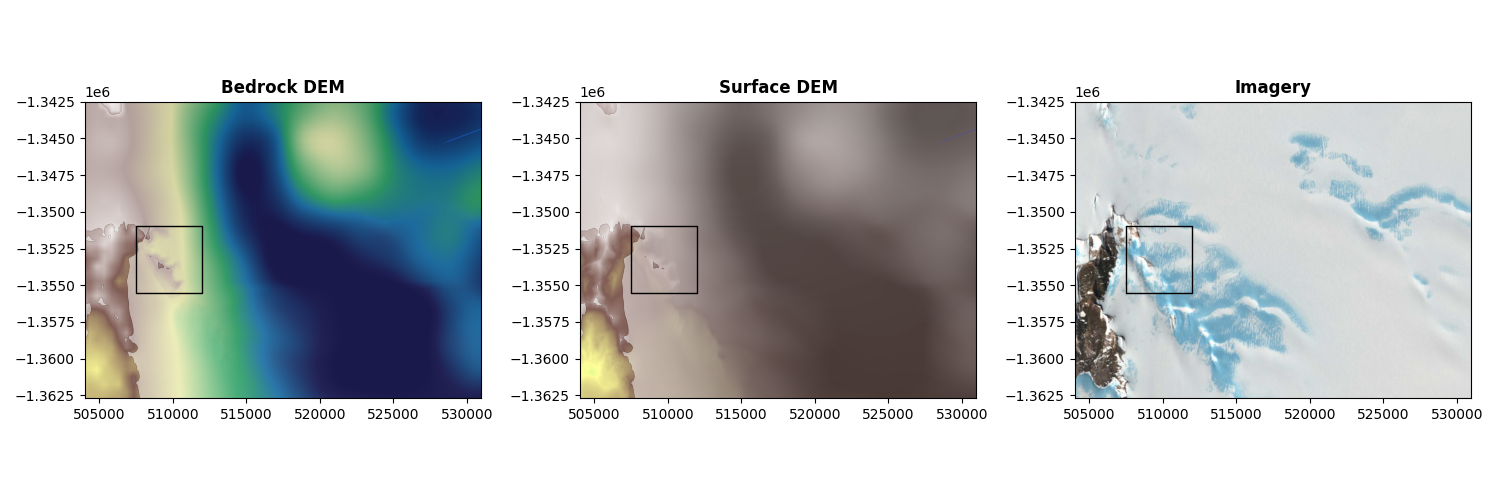

In [ ]:
fig,(ax1,ax2,ax3) = plt.subplots(1,3,figsize=(15,5))

show(bed_dem, ax=ax1, transform=src_bed_coarse.transform, title="Bedrock DEM", cmap='terrain', vmin= 1000,vmax= 2200)
show(surf_dem, ax=ax2, transform=src_surf_coarse.transform, title="Surface DEM", cmap='terrain', vmin= 1000,vmax= 2200)
show(image_data, ax=ax3, transform=src_imagery.transform, title="Imagery")

for n, ax in enumerate([ax1, ax2, ax3]):
    ax.set_xlim([504000, 531000])
    ax.set_ylim([-1.3627e6, -1.3425e6])
    if n < 2:
        show(ice_thickness, ax=ax, transform=src_bed_coarse.transform,cmap='Greys', vmin=0,vmax=1000, alpha=0.5)

    width = 512000-507500
    height = -1.351e6 - -1.3555e6

    fig1_domain = Rectangle((507500,-1.3555e6), width, height)
    pc = PatchCollection([fig1_domain], fc='None')
    ax.add_collection(pc)

    ax

plt.tight_layout()

<Axes: >

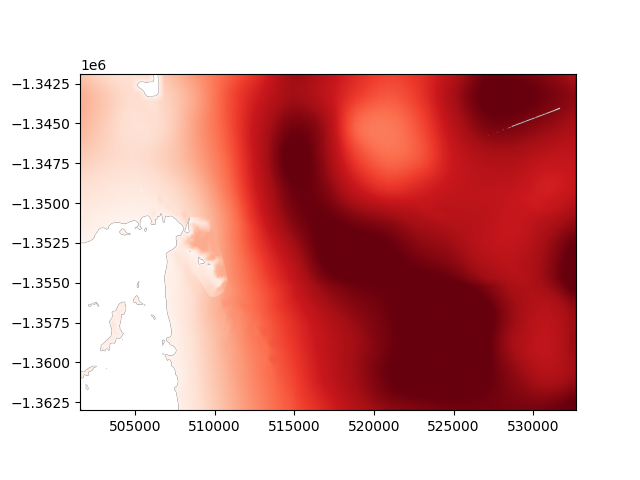

In [29]:
ice_thickness = surf_dem - bed_dem
ice_thickness[ice_thickness < 10] = np.nan
fig,ax = plt.subplots()
show(ice_thickness, ax=ax, transform=src_bed_coarse.transform,cmap='Reds', vmin=0,vmax=1000)